<a href="https://colab.research.google.com/github/koravit-2212/Ai-Skynet-loan/blob/main/loan_default_colab%5BSkynet_Team%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loan Default Prediction: Machine Learning + Transfer Learning
ข้อมูล: `BuildersLab/loan-application-dataset` (LendingClub 2007-2018)

**วิธีใช้:** เปิด GPU ก่อน (Runtime → Change runtime type → T4 GPU) แล้วรันทีละ cell ตามลำดับ
**ลำดับงาน:** โหลดข้อมูล → เตรียมข้อมูล → ตรวจ leakage → XGBoost → TabNet (pretrain → fine-tune) → Ensemble → วัดผล → ทดลอง transfer learning → บันทึกโมเดล

## 0. ติดตั้งไลบรารี

In [1]:
!pip install -q datasets pytorch-tabnet xgboost optuna

## 1. Import และตั้งค่า (แก้ตรงนี้ที่เดียว)

In [2]:
import warnings
import numpy as np
import pandas as pd
import torch
import xgboost as xgb
import optuna
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, classification_report)
from pytorch_tabnet.tab_model import TabNetClassifier
from pytorch_tabnet.pretraining import TabNetPretrainer

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

# ---------------- CONFIG ----------------
HF_NAME   = "BuildersLab/loan-application-dataset"
HF_CONFIG = "feature_engineered"   # หรือ None = default config (ก่อน feature engineering)
TARGET    = None                   # None = เดาชื่อให้อัตโนมัติ; ถ้าเดาไม่เจอให้ใส่ชื่อเอง
BAD_LABELS = ["Charged Off", "Default"]   # ใช้เฉพาะกรณี target เป็นข้อความ (ค่าที่นับว่า "ผิดนัด")
DROP_COLS = []                     # คอลัมน์ที่ไม่ใช้ เช่น id
TARGET_RECALL = 0.70               # recall ขั้นต่ำที่ธุรกิจรับได้ (ใช้เลือก threshold)

QUICK = False                      # True = รันทดสอบเร็ว ๆ ด้วยข้อมูลย่อส่วน (เช็กว่าโค้ดไม่พัง)
N_TRIALS    = 3 if QUICK else 15   # รอบจูน XGBoost
TABNET_ROWS = 50_000 if QUICK else 300_000   # จำนวนแถวที่ให้ TabNet เทรน
PRE_EPOCHS  = 3 if QUICK else 40
FT_EPOCHS   = 5 if QUICK else 80
TR_EPOCHS   = 5 if QUICK else 60   # epoch ในชุดทดลอง transfer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
if DEVICE == "cpu":
    print("คำเตือน: ไม่ได้เปิด GPU จะช้ามาก (Runtime → Change runtime type → T4 GPU)")

device: cuda


## 2. โหลดข้อมูลจาก Hugging Face
ชุดนี้แบ่ง train / validation / test มาให้แล้ว จึงใช้การแบ่งนี้เลย

In [3]:
ds = load_dataset(HF_NAME, HF_CONFIG) if HF_CONFIG else load_dataset(HF_NAME)
print(ds)
splits = {k: ds[k].to_pandas() for k in ds.keys()}
def pick(*names):
    return next(k for k in splits if k.lower() in names)
tr, va, te = splits[pick("train")], splits[pick("validation", "val", "valid")], splits[pick("test")]

if QUICK:
    tr = tr.sample(100_000, random_state=SEED).reset_index(drop=True)
    va = va.sample(30_000, random_state=SEED).reset_index(drop=True)
    te = te.sample(30_000, random_state=SEED).reset_index(drop=True)

print("\nคอลัมน์ทั้งหมด:", len(tr.columns))
print(list(tr.columns))

# หาคอลัมน์เป้าหมาย
if TARGET is None:
    guesses = ["default", "is_default", "target", "loan_status", "bad_loan", "charged_off", "label", "y"]
    found = [c for c in guesses if c in tr.columns]
    if not found:
        raise SystemExit("เดาคอลัมน์เป้าหมายไม่เจอ: ดูรายชื่อด้านบน แล้วตั้ง TARGET ใน cell ที่ 1")
    TARGET = found[0]
print("\nTARGET =", TARGET)
print(tr[TARGET].value_counts(dropna=False).head(10))

README.md:   0%|          | 0.00/6.95k [00:00<?, ?B/s]

data/after_feature_engineering/train.par(…): reconstructing file:   0%|          |  0.00B / 89.2MB            

data/after_feature_engineering/train.par(…): downloading bytes:           |  0.00B            

data/after_feature_engineering/val.parqu(…): reconstructing file:   0%|          |  0.00B / 20.2MB            

data/after_feature_engineering/val.parqu(…): downloading bytes:           |  0.00B            

data/after_feature_engineering/test.parq(…): reconstructing file:   0%|          |  0.00B / 20.1MB            

data/after_feature_engineering/test.parq(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['loan_amnt', 'int_rate', 'installment', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'application_type', 'addr_state', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'chargeoff_within_12_mths', 'delinq_amnt', 'mort_acc', 'pub_rec_bankruptcies', 'tax_liens', 'mths_since_last_delinq', 'mths_since_last_record', 'mths_since_last_major_derog', 'mths_since_recent_bc_dlq', 'mths_since_recent_revol_delinq', 'mths_since_recent_inq', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mths_since_recent_bc', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl', 'num_bc_sats', 'num_bc_tl', 'num_il_tl', 'num_op_rev_tl', 'num_rev_accts', 'num_rev_tl_bal_gt_0', 'num_sats', 'num_tl_120dpd_2m', 'num_tl_30dpd', 'num_tl_90g_dpd_24m', 'num_tl_op_past_12m

## 3. เตรียมข้อมูล

In [4]:
def to_binary(s):
    if s.dtype == bool or pd.api.types.is_numeric_dtype(s):
        y = s.astype(int).values
    else:
        y = s.isin(BAD_LABELS).astype(int).values
    if not set(np.unique(y)) <= {0, 1}:
        raise SystemExit("TARGET ไม่ใช่ 0/1 ตรวจชื่อคอลัมน์ หรือปรับ BAD_LABELS")
    return y

def split_xy(d):
    d = d.drop(columns=[c for c in DROP_COLS if c in d.columns])
    return d.drop(columns=[TARGET]), to_binary(d[TARGET])

X_tr, y_tr = split_xy(tr); X_va, y_va = split_xy(va); X_te, y_te = split_xy(te)
print("rows train/valid/test:", len(X_tr), len(X_va), len(X_te))
print("positive rate train: %.2f%% | valid: %.2f%% | test: %.2f%%" %
      (100 * y_tr.mean(), 100 * y_va.mean(), 100 * y_te.mean()))

# bool -> int, ข้อความ -> label encode (fit รวมทุก split ให้รหัสตรงกัน; ไม่ใช้ target จึงไม่ leak)
all_X = pd.concat([X_tr, X_va, X_te], keys=["tr", "va", "te"])
for c in all_X.columns:
    if all_X[c].dtype == bool:
        all_X[c] = all_X[c].astype(int)
cat_cols = all_X.select_dtypes(include=["object", "category"]).columns.tolist()
for c in cat_cols:
    all_X[c] = LabelEncoder().fit_transform(all_X[c].astype(str))
all_X = all_X.astype("float32")
X_tr, X_va, X_te = all_X.loc["tr"], all_X.loc["va"], all_X.loc["te"]
print("features:", X_tr.shape[1], "| categorical (label-encoded):", len(cat_cols))

rows train/valid/test: 941744 201803 201802
positive rate train: 19.96% | valid: 19.97% | test: 19.97%
features: 107 | categorical (label-encoded): 7


## 4. ตรวจ data leakage
ชุดต้นฉบับมีคอลัมน์ที่รู้ได้เฉพาะ **หลังปล่อยกู้** ถ้า feature ตัวเดียวทำนายได้เก่งผิดปกติ (AUC > 0.9) ให้สงสัยว่ารั่ว แล้วเอาออกด้วย `DROP_COLS`

In [5]:
rng = np.random.RandomState(SEED)
sidx = rng.choice(len(X_tr), size=min(100_000, len(X_tr)), replace=False)
sub, ysub = X_tr.iloc[sidx], y_tr[sidx]
single = {}
for c in sub.columns:
    s = sub[c].fillna(sub[c].median())
    if s.nunique() > 1:
        a = roc_auc_score(ysub, s)
        single[c] = max(a, 1 - a)
print(pd.Series(single).sort_values(ascending=False).head(10).round(4))

int_rate                 0.6796
loan_to_income           0.5970
fico_score               0.5947
term_months              0.5899
installment_to_income    0.5878
dti                      0.5758
acc_open_past_24mths     0.5735
bc_open_to_buy           0.5624
verification_status      0.5621
num_tl_op_past_12m       0.5615
dtype: float64


## 5. XGBoost + Optuna
จูนโดยใช้ **PR-AUC** เป็นเป้า (เหมาะกับข้อมูลที่คลาสไม่สมดุล) และถ่วงน้ำหนักคลาสด้วย `scale_pos_weight`

In [ ]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print("scale_pos_weight เต็ม =", round(spw, 2))

def make_xgb(p):
    p = dict(p)
    return xgb.XGBClassifier(
        n_estimators=3000, tree_method="hist", device=DEVICE, eval_metric="aucpr",
        early_stopping_rounds=100, random_state=SEED, n_jobs=-1,
        scale_pos_weight=p.pop("spw", spw), **p)

def objective(trial):
    p = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 30),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 20, log=True),
        spw=trial.suggest_float("spw", 1, spw))
    m = make_xgb(p)
    m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return average_precision_score(y_va, m.predict_proba(X_va)[:, 1])

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
print("best valid PR-AUC: %.4f" % study.best_value)
print(study.best_params)

xgb_model = make_xgb(study.best_params)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
p_xgb_va = xgb_model.predict_proba(X_va)[:, 1]
p_xgb_te = xgb_model.predict_proba(X_te)[:, 1]
print("XGBoost  valid ROC-AUC %.4f | PR-AUC %.4f" % (roc_auc_score(y_va, p_xgb_va), average_precision_score(y_va, p_xgb_va)))

scale_pos_weight เต็ม = 4.01


  0%|          | 0/15 [00:00<?, ?it/s]

best valid PR-AUC: 0.4211
{'learning_rate': 0.0394184986801169, 'max_depth': 5, 'min_child_weight': 12, 'subsample': 0.9387602166297027, 'colsample_bytree': 0.8634239833374782, 'reg_lambda': 0.4172767928935185, 'spw': 2.534405310826859}
XGBoost  valid ROC-AUC 0.7414 | PR-AUC 0.4211


In [6]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

def make_xgb(p):
    p = dict(p)
    return xgb.XGBClassifier(
        n_estimators=3000, tree_method="hist", device=DEVICE, eval_metric="aucpr",
        early_stopping_rounds=100, random_state=SEED, n_jobs=-1,
        scale_pos_weight=p.pop("spw", spw), **p)

class _S: pass
study = _S()
study.best_params = {'learning_rate': 0.0394184986801169, 'max_depth': 5,
                     'min_child_weight': 12, 'subsample': 0.9387602166297027,
                     'colsample_bytree': 0.8634239833374782,
                     'reg_lambda': 0.4172767928935185, 'spw': 2.534405310826859}

xgb_model = make_xgb(study.best_params)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
p_xgb_va = xgb_model.predict_proba(X_va)[:, 1]
p_xgb_te = xgb_model.predict_proba(X_te)[:, 1]
print("XGBoost valid ROC-AUC %.4f | PR-AUC %.4f" % (roc_auc_score(y_va, p_xgb_va), average_precision_score(y_va, p_xgb_va)))

XGBoost valid ROC-AUC 0.7414 | PR-AUC 0.4211


In [7]:
miss_cols = [c for c in X_tr.columns if c.endswith("_missing")]
keep = [c for c in X_tr.columns if c not in miss_cols]
m = make_xgb(study.best_params)
m.fit(X_tr[keep], y_tr, eval_set=[(X_va[keep], y_va)], verbose=False)
p = m.predict_proba(X_te[keep])[:, 1]
print("ไม่มี *_missing: ROC-AUC %.4f | PR-AUC %.4f" % (roc_auc_score(y_te, p), average_precision_score(y_te, p)))

ไม่มี *_missing: ROC-AUC 0.7370 | PR-AUC 0.4151


## 6. TabNet ขั้นที่ 1: Pretraining (ส่วนของ Transfer Learning)
ให้โมเดลเรียนโครงสร้างของข้อมูลโดย **ไม่ใช้ label** (self-supervised) แล้วค่อยถ่ายน้ำหนักไปเทรนจริงในขั้นถัดไป

In [ ]:
med = X_tr.median()
fill = lambda d: d.fillna(med).values.astype(np.float32)
Xtr_np, Xva_np, Xte_np = fill(X_tr), fill(X_va), fill(X_te)

idx = rng.choice(len(Xtr_np), size=min(TABNET_ROWS, len(Xtr_np)), replace=False)
Xtr_s, ytr_s = Xtr_np[idx], y_tr[idx]

cat_idxs = [X_tr.columns.get_loc(c) for c in cat_cols]
cat_dims = [int(all_X[c].max()) + 1 for c in cat_cols]
tab_params = dict(
    n_d=32, n_a=32, n_steps=5, gamma=1.5, n_independent=2, n_shared=2,
    cat_idxs=cat_idxs, cat_dims=cat_dims, cat_emb_dim=4,
    optimizer_fn=torch.optim.AdamW, optimizer_params=dict(lr=2e-3, weight_decay=1e-5),
    scheduler_fn=torch.optim.lr_scheduler.StepLR, scheduler_params=dict(step_size=10, gamma=0.9),
    mask_type="entmax", seed=SEED, verbose=1)

pretrainer = TabNetPretrainer(**tab_params)
pretrainer.fit(X_train=Xtr_s, eval_set=[Xva_np[:50_000]], pretraining_ratio=0.7,
               max_epochs=PRE_EPOCHS, patience=8, batch_size=4096, virtual_batch_size=512)

epoch 0  | loss: 325.07519| val_0_unsup_loss_numpy: 77.93254089355469|  0:00:09s
epoch 1  | loss: 30.38381| val_0_unsup_loss_numpy: 11.122610092163086|  0:00:16s
epoch 2  | loss: 9.10488 | val_0_unsup_loss_numpy: 6.763869762420654|  0:00:24s
epoch 3  | loss: 5.97568 | val_0_unsup_loss_numpy: 5.136380195617676|  0:00:33s
epoch 4  | loss: 4.70673 | val_0_unsup_loss_numpy: 4.353280067443848|  0:00:40s
epoch 5  | loss: 4.16171 | val_0_unsup_loss_numpy: 3.9357199668884277|  0:00:49s
epoch 6  | loss: 3.81413 | val_0_unsup_loss_numpy: 3.711549997329712|  0:00:57s
epoch 7  | loss: 3.59134 | val_0_unsup_loss_numpy: 3.503690004348755|  0:01:05s
epoch 8  | loss: 3.30159 | val_0_unsup_loss_numpy: 3.2851200103759766|  0:01:13s
epoch 9  | loss: 2.98665 | val_0_unsup_loss_numpy: 3.1179800033569336|  0:01:20s
epoch 10 | loss: 2.73086 | val_0_unsup_loss_numpy: 3.0304501056671143|  0:01:28s
epoch 11 | loss: 2.54238 | val_0_unsup_loss_numpy: 2.969599962234497|  0:01:36s
epoch 12 | loss: 2.36703 | val_0_u

## 7. TabNet ขั้นที่ 2: Fine-tune ด้วย label (ถ่ายน้ำหนักจากขั้นที่ 1)

In [ ]:
tabnet = TabNetClassifier(**tab_params)
tabnet.fit(Xtr_s, ytr_s, eval_set=[(Xtr_s, ytr_s), (Xva_np, y_va)], eval_name=["train", "valid"],
           eval_metric=["auc"], from_unsupervised=pretrainer,
           max_epochs=FT_EPOCHS, patience=12, batch_size=4096, virtual_batch_size=512,
           weights=0)   # ถ้า recall ต่ำมาก ลองเปลี่ยนเป็น weights=1
p_tab_va = tabnet.predict_proba(Xva_np)[:, 1]
p_tab_te = tabnet.predict_proba(Xte_np)[:, 1]

# เช็ก overfit: เทียบ train_auc กับ valid_auc
h = pd.DataFrame(tabnet.history.history)
print("best epoch:", tabnet.best_epoch)
print(h[["train_auc", "valid_auc"]].tail(5))
print("TabNet  valid ROC-AUC %.4f | PR-AUC %.4f" % (roc_auc_score(y_va, p_tab_va), average_precision_score(y_va, p_tab_va)))

epoch 0  | loss: 0.77482 | train_auc: 0.55203 | valid_auc: 0.55155 |  0:00:13s
epoch 1  | loss: 0.49196 | train_auc: 0.61912 | valid_auc: 0.61935 |  0:00:25s
epoch 2  | loss: 0.48226 | train_auc: 0.65653 | valid_auc: 0.65574 |  0:00:38s
epoch 3  | loss: 0.47548 | train_auc: 0.67452 | valid_auc: 0.67271 |  0:00:50s
epoch 4  | loss: 0.47139 | train_auc: 0.6861  | valid_auc: 0.68304 |  0:01:03s
epoch 5  | loss: 0.46942 | train_auc: 0.689   | valid_auc: 0.68624 |  0:01:15s
epoch 6  | loss: 0.46874 | train_auc: 0.69027 | valid_auc: 0.68832 |  0:01:27s
epoch 7  | loss: 0.46768 | train_auc: 0.69305 | valid_auc: 0.69079 |  0:01:39s
epoch 8  | loss: 0.46513 | train_auc: 0.69513 | valid_auc: 0.69248 |  0:01:51s
epoch 9  | loss: 0.46418 | train_auc: 0.69487 | valid_auc: 0.69214 |  0:02:03s
epoch 10 | loss: 0.46318 | train_auc: 0.69965 | valid_auc: 0.69671 |  0:02:14s
epoch 11 | loss: 0.46212 | train_auc: 0.70092 | valid_auc: 0.69817 |  0:02:26s
epoch 12 | loss: 0.46154 | train_auc: 0.70207 | vali

## 8. Ensemble + เลือก threshold จาก validation + วัดผลบน test
เลือก threshold จาก validation เท่านั้น แล้ววัดบน test ครั้งเดียว เพื่อไม่ให้ตัวเลขดีเกินจริง

In [ ]:
best_w, best_ap = 0.5, -1
for w in np.linspace(0, 1, 11):
    ap = average_precision_score(y_va, w * p_xgb_va + (1 - w) * p_tab_va)
    if ap > best_ap:
        best_w, best_ap = w, ap
print("Ensemble: weight XGB = %.1f | valid PR-AUC = %.4f" % (best_w, best_ap))
p_ens_va = best_w * p_xgb_va + (1 - best_w) * p_tab_va
p_ens_te = best_w * p_xgb_te + (1 - best_w) * p_tab_te

def pick_threshold(y_true, proba, target_recall):
    p, r, t = precision_recall_curve(y_true, proba)
    ok = np.where(r[:-1] >= target_recall)[0]
    return t[ok[-1]] if len(ok) else 0.5

summary = []
for name, pv, pt in [("XGBoost", p_xgb_va, p_xgb_te),
                     ("TabNet (transfer)", p_tab_va, p_tab_te),
                     ("Ensemble", p_ens_va, p_ens_te)]:
    thr = pick_threshold(y_va, pv, TARGET_RECALL)
    pred = (pt >= thr).astype(int)
    print(f"\n=== {name} | threshold (เลือกจาก valid) = {thr:.4f} ===")
    print("ROC-AUC: %.4f | PR-AUC: %.4f" % (roc_auc_score(y_te, pt), average_precision_score(y_te, pt)))
    print(classification_report(y_te, pred, digits=3))
    rep = classification_report(y_te, pred, output_dict=True)["1"]
    summary.append(dict(model=name, roc_auc=roc_auc_score(y_te, pt), pr_auc=average_precision_score(y_te, pt),
                        precision=rep["precision"], recall=rep["recall"], f1=rep["f1-score"], threshold=thr))
summary = pd.DataFrame(summary).round(4)
print("\nสรุปเปรียบเทียบ (test):"); print(summary.to_string(index=False))

Ensemble: weight XGB = 1.0 | valid PR-AUC = 0.4211

=== XGBoost | threshold (เลือกจาก valid) = 0.3752 ===
ROC-AUC: 0.7391 | PR-AUC: 0.4187
              precision    recall  f1-score   support

           0      0.896     0.650     0.754    161512
           1      0.332     0.698     0.450     40290

    accuracy                          0.660    201802
   macro avg      0.614     0.674     0.602    201802
weighted avg      0.784     0.660     0.693    201802


=== TabNet (transfer) | threshold (เลือกจาก valid) = 0.1831 ===
ROC-AUC: 0.7176 | PR-AUC: 0.3847
              precision    recall  f1-score   support

           0      0.890     0.618     0.729    161512
           1      0.312     0.695     0.431     40290

    accuracy                          0.633    201802
   macro avg      0.601     0.657     0.580    201802
weighted avg      0.775     0.633     0.670    201802


=== Ensemble | threshold (เลือกจาก valid) = 0.3752 ===
ROC-AUC: 0.7391 | PR-AUC: 0.4187
              precis

## 9. พิสูจน์ว่า Transfer Learning ช่วยจริง
เทียบ **TabNet จากศูนย์** vs **TabNet แบบ transfer** vs **XGBoost** เมื่อมีข้อมูลที่มี label น้อย (1%, 5%, 10%, 30%)

เซลล์นี้ใช้เวลานานที่สุด ถ้าเวลาจำกัดให้ลดรายการใน `fracs`

labeled fraction = 1% (n = 9,417, positives = 1,803)
Stop training because you reached max_epochs = 60 with best_epoch = 59 and best_valid_auc = 0.64634
Stop training because you reached max_epochs = 60 with best_epoch = 59 and best_valid_auc = 0.6319
labeled fraction = 5% (n = 47,087, positives = 9,321)

Early stopping occurred at epoch 58 with best_epoch = 48 and best_valid_auc = 0.69766
Stop training because you reached max_epochs = 60 with best_epoch = 55 and best_valid_auc = 0.69795
labeled fraction = 10% (n = 94,174, positives = 18,673)
Stop training because you reached max_epochs = 60 with best_epoch = 52 and best_valid_auc = 0.70824
Stop training because you reached max_epochs = 60 with best_epoch = 58 and best_valid_auc = 0.71069
labeled fraction = 30% (n = 282,523, positives = 56,319)
Stop training because you reached max_epochs = 60 with best_epoch = 59 and best_valid_auc = 0.72553
Stop training because you reached max_epochs = 60 with best_epoch = 57 and best_valid_auc = 0.

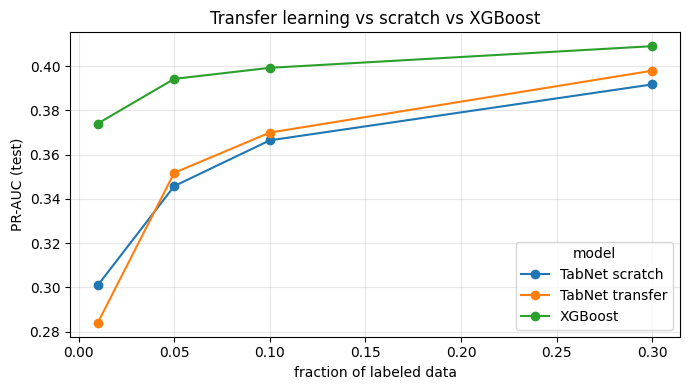

In [ ]:
fracs = [0.01, 0.05, 0.10, 0.30]
quiet = dict(tab_params, verbose=0)
rng2 = np.random.RandomState(SEED)
rows = []

for f in fracs:
    n = int(len(Xtr_np) * f)
    i2 = rng2.choice(len(Xtr_np), n, replace=False)
    Xs, ys = Xtr_np[i2], y_tr[i2]
    print(f"labeled fraction = {f:.0%} (n = {n:,}, positives = {ys.sum():,})")

    for name, pre in [("TabNet scratch", None), ("TabNet transfer", pretrainer)]:
        m = TabNetClassifier(**quiet)
        kw = {"from_unsupervised": pre} if pre is not None else {}
        m.fit(Xs, ys, eval_set=[(Xva_np, y_va)], eval_name=["valid"], eval_metric=["auc"],
              max_epochs=TR_EPOCHS, patience=10, batch_size=1024, virtual_batch_size=128, **kw)
        pt = m.predict_proba(Xte_np)[:, 1]
        rows.append(dict(frac=f, n=n, model=name,
                         roc_auc=roc_auc_score(y_te, pt), pr_auc=average_precision_score(y_te, pt)))

    mx = make_xgb(study.best_params)
    mx.fit(X_tr.iloc[i2], ys, eval_set=[(X_va, y_va)], verbose=False)
    px = mx.predict_proba(X_te)[:, 1]
    rows.append(dict(frac=f, n=n, model="XGBoost",
                     roc_auc=roc_auc_score(y_te, px), pr_auc=average_precision_score(y_te, px)))

res = pd.DataFrame(rows)
table = res.pivot(index="frac", columns="model", values="pr_auc").round(4)
print("\n=== PR-AUC บน test (ยิ่งสูงยิ่งดี) ===");  print(table)
print("\n=== ROC-AUC บน test ===");  print(res.pivot(index="frac", columns="model", values="roc_auc").round(4))

ax = table.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("fraction of labeled data"); ax.set_ylabel("PR-AUC (test)")
ax.set_title("Transfer learning vs scratch vs XGBoost"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("transfer_comparison.png", dpi=150); plt.show()
res.to_csv("transfer_results.csv", index=False)

## 10. Feature importance และบันทึกโมเดล

inq_last_12m_missing        0.1163
term_months                 0.0955
int_rate                    0.0842
open_acc_6m_missing         0.0813
all_util_missing            0.0638
total_cu_tl_missing         0.0549
emp_length_missing          0.0315
open_act_il_missing         0.0211
home_ownership              0.0203
acc_open_past_24mths        0.0181
fico_score                  0.0180
num_tl_120dpd_2m_missing    0.0153
mort_acc                    0.0125
loan_to_income              0.0114
il_util_missing             0.0095
dtype: float32


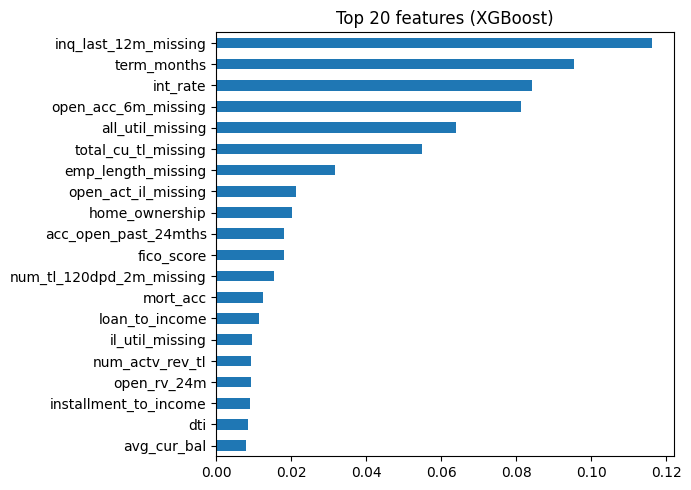

Successfully saved model at tabnet_loan.zip
บันทึกแล้ว: xgb_loan.json, tabnet_loan.zip, final_summary.csv, transfer_results.csv, *.png


In [ ]:
imp = pd.Series(xgb_model.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print(imp.head(15).round(4))
imp.head(20).sort_values().plot(kind="barh", figsize=(7, 5), title="Top 20 features (XGBoost)")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()

xgb_model.save_model("xgb_loan.json")
tabnet.save_model("tabnet_loan")
summary.to_csv("final_summary.csv", index=False)
print("บันทึกแล้ว: xgb_loan.json, tabnet_loan.zip, final_summary.csv, transfer_results.csv, *.png")

# ดาวน์โหลดไฟล์ผลลัพธ์ลงเครื่อง (ถ้าต้องการ)
# from google.colab import files
# for f in ["final_summary.csv", "transfer_results.csv", "transfer_comparison.png", "feature_importance.png"]:
#     files.download(f)

## 11. ตรวจความเป็นธรรมเบื้องต้น (ใช้ในหน้า Responsible AI)
เทียบผลของโมเดลระหว่างกลุ่มย่อย เช่น ประเภทที่อยู่อาศัย หรือวัตถุประสงค์การกู้ ตัวเลขนี้เป็นการตรวจเชิงพรรณนา ไม่ใช่การพิสูจน์ว่าโมเดลเป็นธรรม เพราะความต่างระหว่างกลุ่มอาจมาจากอัตราผิดนัดจริงที่ต่างกัน

ตั้ง `GROUP_COL` เป็นชื่อคอลัมน์ที่มีกลุ่มไม่เกิน 12 ค่า ถ้าเว้นเป็น `None` จะพิมพ์รายชื่อคอลัมน์ที่เลือกได้

In [ ]:
GROUP_COL = None     # เช่น "home_ownership" (ถ้า config ที่ใช้แยกเป็นคอลัมน์ one-hot ให้เลือกคอลัมน์ 0/1 ที่สนใจ)

cands = [c for c in X_te.columns if X_te[c].nunique() <= 12]
fairness_df = None
if GROUP_COL is None or GROUP_COL not in X_te.columns:
    print("ตั้ง GROUP_COL เป็นหนึ่งในคอลัมน์ต่อไปนี้ แล้วรัน cell นี้ใหม่:")
    print(cands[:60])
else:
    thr_f = pick_threshold(y_va, p_xgb_va, TARGET_RECALL)
    pred_f = (p_xgb_te >= thr_f).astype(int)
    rows = []
    for g, ix in X_te.groupby(GROUP_COL).indices.items():
        yt, yp = y_te[ix], pred_f[ix]
        if len(ix) < 500 or yt.sum() < 30:
            continue   # กลุ่มเล็กเกินไป ตัวเลขไม่นิ่ง
        rows.append(dict(group=str(g), n=int(len(ix)), default_rate=float(yt.mean()),
                         flag_rate=float(yp.mean()), recall=float(yp[yt == 1].mean()),
                         precision=float(yt[yp == 1].mean()) if yp.sum() else np.nan))
    fairness_df = pd.DataFrame(rows).round(3)
    print(fairness_df.to_string(index=False))
    if len(fairness_df) >= 2:
        print("\nอัตราที่ถูกเตือน สูงสุด/ต่ำสุด = %.2f เท่า" % (fairness_df.flag_rate.max() / fairness_df.flag_rate.min()))

ตั้ง GROUP_COL เป็นหนึ่งในคอลัมน์ต่อไปนี้ แล้วรัน cell นี้ใหม่:
['home_ownership', 'verification_status', 'application_type', 'inq_last_6mths', 'collections_12_mths_ex_med', 'acc_now_delinq', 'chargeoff_within_12_mths', 'pub_rec_bankruptcies', 'num_tl_120dpd_2m', 'num_tl_30dpd', 'initial_list_status', 'disbursement_method', 'mths_since_last_record_missing', 'mths_since_recent_bc_dlq_missing', 'mths_since_last_major_derog_missing', 'mths_since_recent_revol_delinq_missing', 'il_util_missing', 'mths_since_rcnt_il_missing', 'all_util_missing', 'total_cu_tl_missing', 'inq_last_12m_missing', 'open_acc_6m_missing', 'open_act_il_missing', 'open_rv_24m_missing', 'open_rv_12m_missing', 'open_il_24m_missing', 'open_il_12m_missing', 'total_bal_il_missing', 'max_bal_bc_missing', 'inq_fi_missing', 'mths_since_last_delinq_missing', 'mths_since_recent_inq_missing', 'num_tl_120dpd_2m_missing', 'mo_sin_old_il_acct_missing', 'emp_length_missing', 'emp_length_years', 'term_months']


## 12. บันทึกโมเดล (ใช้ครั้งหน้า และเตรียม deploy)
**ต้องบันทึก** เพราะไฟล์ใน `/content` ของ Colab หายเมื่อ runtime รีเซ็ต cell นี้บันทึกโมเดล XGBoost + ข้อมูลประกอบ (`meta.json`: รายชื่อ feature, ค่ามัธยฐาน, threshold, ผลวัด) ลง Google Drive และลงโฟลเดอร์ `loan_app` ที่ใช้ deploy

เว็บแอปใช้เฉพาะ XGBoost เพื่อให้เบาและเร็ว (ไม่ต้องลง PyTorch บนเซิร์ฟเวอร์)

In [ ]:
import json, os, shutil
from sklearn.metrics import precision_score, recall_score, f1_score

try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/loan-Project/model_artifacts"
except Exception:
    SAVE_DIR = "/content/model_artifacts"
    print("เมานต์ Drive ไม่ได้ จะบันทึกที่", SAVE_DIR, "(ไฟล์จะหายเมื่อ runtime รีเซ็ต)")
APP_DIR = "/content/loan_app"
os.makedirs(SAVE_DIR, exist_ok=True); os.makedirs(APP_DIR, exist_ok=True)

# 1) โมเดล: ตัดต้นไม้ให้เหลือถึงรอบที่ดีที่สุดตาม early stopping
booster = xgb_model.get_booster()[: xgb_model.best_iteration + 1]
booster.save_model(f"{APP_DIR}/model.json")

# 2) ข้อมูลประกอบ
thr = float(pick_threshold(y_va, p_xgb_va, TARGET_RECALL))
pred = (p_xgb_te >= thr).astype(int)
imp = pd.Series(xgb_model.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
form_feats = [c for c in imp.index if c not in cat_cols][:10]      # ฟอร์มเว็บใช้ 10 feature ที่สำคัญสุด
q = X_tr[form_feats].quantile([0.01, 0.5, 0.99])

fair = globals().get("fairness_df")
meta = {
    "dataset": f"{HF_NAME} ({HF_CONFIG or 'default'})",
    "target": TARGET,
    "feature_names": list(X_tr.columns),
    "medians": {c: float(v) for c, v in X_tr.median().fillna(0).items()},
    "form_features": [dict(name=c, min=float(q.loc[0.01, c]), median=float(q.loc[0.5, c]),
                           max=float(q.loc[0.99, c])) for c in form_feats],
    "threshold": thr,
    "target_recall": float(TARGET_RECALL),
    "metrics": dict(roc_auc=float(roc_auc_score(y_te, p_xgb_te)),
                    pr_auc=float(average_precision_score(y_te, p_xgb_te)),
                    precision=float(precision_score(y_te, pred)),
                    recall=float(recall_score(y_te, pred)),
                    f1=float(f1_score(y_te, pred))),
    "n_train": int(len(X_tr)), "n_test": int(len(X_te)),
    "positive_rate": float(y_tr.mean()),
    "top_features": list(imp.head(8).index),
    "fairness_col": GROUP_COL if fair is not None else None,
    "fairness": json.loads(fair.to_json(orient="records")) if fair is not None else None,
}
with open(f"{APP_DIR}/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=1)

# 3) ตรวจว่าโมเดลที่บันทึกให้ผลตรงกับโมเดลในหน่วยความจำ
chk = xgb.Booster(); chk.load_model(f"{APP_DIR}/model.json")
a = chk.predict(xgb.DMatrix(X_te.iloc[:5000]))
b = xgb_model.predict_proba(X_te.iloc[:5000])[:, 1]
print("ความต่างสูงสุดระหว่างโมเดลที่โหลดกับต้นฉบับ: %.2e" % float(np.abs(a - b).max()))
assert np.allclose(a, b, atol=1e-4), "โมเดลที่บันทึกให้ผลไม่ตรงกับต้นฉบับ"

# 4) สำเนาลง Drive (รวม TabNet ถ้ามี)
for fn in ["model.json", "meta.json"]:
    shutil.copy(f"{APP_DIR}/{fn}", f"{SAVE_DIR}/{fn}")
if os.path.exists("tabnet_loan.zip"):
    shutil.copy("tabnet_loan.zip", f"{SAVE_DIR}/tabnet_loan.zip")
print("บันทึกแล้วที่:", SAVE_DIR, "->", os.listdir(SAVE_DIR))
print("threshold = %.4f | test precision %.3f | recall %.3f" % (thr, meta["metrics"]["precision"], meta["metrics"]["recall"]))

Mounted at /content/drive
ความต่างสูงสุดระหว่างโมเดลที่โหลดกับต้นฉบับ: 1.34e-06
บันทึกแล้วที่: /content/drive/MyDrive/loan-Project/model_artifacts -> ['model.json', 'meta.json', 'tabnet_loan.zip']
threshold = 0.3752 | test precision 0.332 | recall 0.698


## 14. Deploy ขึ้น Streamlit (ได้ลิงก์ให้คนอื่นลองใช้ฟรี)
https://ai-skynet-loan-genvxf4fjsaxcnfpnjjrpq.streamlit.app/

## 15. ครั้งหน้าไม่ต้องเทรนใหม่
เปิดโน้ตบุ๊กใหม่ รัน cell นี้เพื่อโหลดโมเดลที่บันทึกไว้ใน Drive มาใช้ทำนายได้เลย

In [ ]:
import json, numpy as np, pandas as pd, xgboost as xgb
from google.colab import drive
drive.mount("/content/drive")
SAVE_DIR = "/content/drive/MyDrive/loan-Project/model_artifacts"

bst = xgb.Booster(); bst.load_model(f"{SAVE_DIR}/model.json")
meta = json.load(open(f"{SAVE_DIR}/meta.json", encoding="utf-8"))

def predict(df):
    X = df.reindex(columns=meta["feature_names"]).apply(pd.to_numeric, errors="coerce")
    X = X.fillna(pd.Series(meta["medians"])).astype("float32")
    s = bst.predict(xgb.DMatrix(X[meta["feature_names"]]))
    return s, (s >= meta["threshold"]).astype(int)   # risk score, flag
print("โหลดโมเดลสำเร็จ | threshold =", round(meta["threshold"], 4))

Mounted at /content/drive
โหลดโมเดลสำเร็จ | threshold = 0.3752


## 16. กราฟเทียบ 2 โมเดล: Learning Curve
เทียบ **XGBoost** กับ **TabNet (transfer)** ว่า F1-macro บนชุด train และ validation เปลี่ยนไปอย่างไรเมื่อใช้ข้อมูลเทรนมากขึ้น ใช้ตอนวิเคราะห์ว่าโมเดลยัง underfit, overfit หรือข้อมูลพอแล้ว

- ต้องรัน cell 1-8 ก่อน (ใช้ตัวแปรจาก cell เหล่านั้น)
- F1-macro คำนวณที่ threshold ซึ่งเลือกจาก validation ให้ recall ≥ `TARGET_RECALL` (ตัวเดียวกับ cell 8) ตัวเลขจึงสอดคล้องกับผลที่รายงาน
- ใช้เวลานานเพราะเทรน TabNet หลายรอบ ถ้าช้าไปให้ลดรายการใน `SIZES`

train size = 5,000 (positives = 922)

Early stopping occurred at epoch 10 with best_epoch = 0 and best_valid_auc = 0.5161
train size = 20,000 (positives = 3,927)
Stop training because you reached max_epochs = 60 with best_epoch = 59 and best_valid_auc = 0.66927
train size = 50,000 (positives = 9,957)

Early stopping occurred at epoch 54 with best_epoch = 44 and best_valid_auc = 0.69999
train size = 100,000 (positives = 19,989)
Stop training because you reached max_epochs = 60 with best_epoch = 50 and best_valid_auc = 0.71192
train size = 200,000 (positives = 40,065)
Stop training because you reached max_epochs = 60 with best_epoch = 57 and best_valid_auc = 0.72174
            model      n  train_f1  valid_f1
          XGBoost   5000    0.6345    0.5701
TabNet (transfer)   5000    0.3745    0.3881
          XGBoost  20000    0.6321    0.5823
TabNet (transfer)  20000    0.5440    0.5317
          XGBoost  50000    0.6328    0.5866
TabNet (transfer)  50000    0.5699    0.5632
          XG

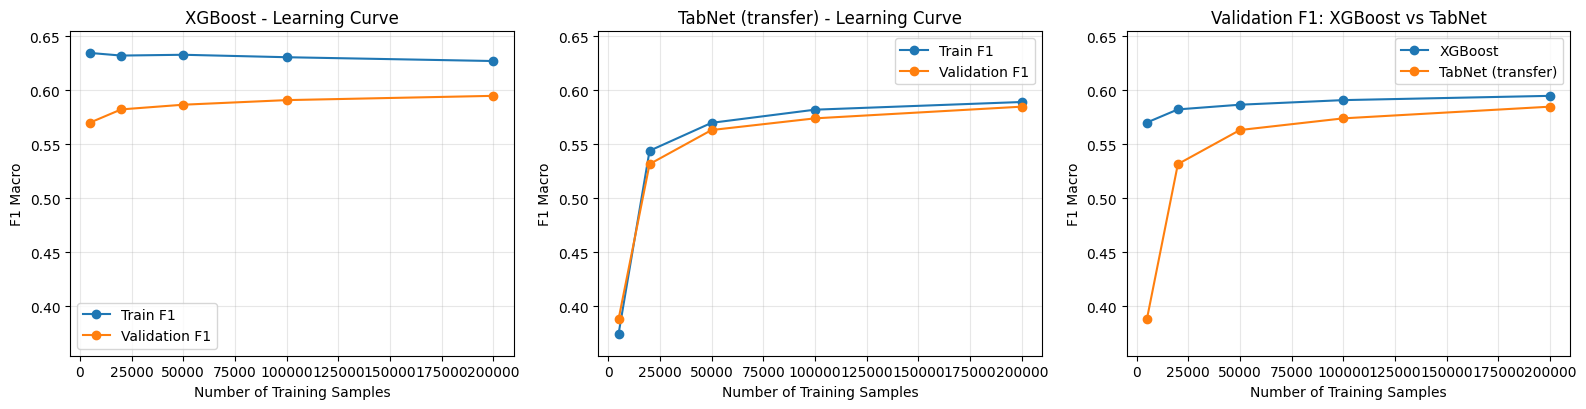

In [ ]:
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt
from pytorch_tabnet.tab_model import TabNetClassifier

SIZES = [5_000, 20_000, 50_000, 100_000, 200_000]     # จำนวนแถวที่ใช้เทรนในแต่ละจุด
if QUICK:
    SIZES = [2_000, 5_000, 10_000]
SIZES = [s for s in SIZES if s <= len(Xtr_np)]
TRAIN_EVAL_MAX = 50_000        # จำนวนแถวสูงสุดที่ใช้วัด train F1 (เพื่อไม่ให้ช้า)

def f1_macro(y, proba, thr):
    return f1_score(y, (proba >= thr).astype(int), average="macro")

quiet = dict(tab_params, verbose=0)
order = np.random.RandomState(SEED).permutation(len(Xtr_np))
lc = []
for n in SIZES:
    ix = order[:n]; ys = y_tr[ix]
    tix = ix[:min(n, TRAIN_EVAL_MAX)]
    print(f"train size = {n:,} (positives = {int(ys.sum()):,})")

    # --- XGBoost ---
    mx = make_xgb(study.best_params)
    mx.fit(X_tr.iloc[ix], ys, eval_set=[(X_va, y_va)], verbose=False)
    pv = mx.predict_proba(X_va)[:, 1]
    thr = pick_threshold(y_va, pv, TARGET_RECALL)
    lc.append(dict(model="XGBoost", n=n,
                   train_f1=f1_macro(y_tr[tix], mx.predict_proba(X_tr.iloc[tix])[:, 1], thr),
                   valid_f1=f1_macro(y_va, pv, thr)))

    # --- TabNet (transfer: ถ่ายน้ำหนักจาก pretrainer) ---
    bs = min(1024, max(64, n // 4))
    mt = TabNetClassifier(**quiet)
    mt.fit(Xtr_np[ix], ys, eval_set=[(Xva_np, y_va)], eval_name=["valid"], eval_metric=["auc"],
           from_unsupervised=pretrainer, max_epochs=TR_EPOCHS, patience=10,
           batch_size=bs, virtual_batch_size=min(128, bs))
    pv = mt.predict_proba(Xva_np)[:, 1]
    thr = pick_threshold(y_va, pv, TARGET_RECALL)
    lc.append(dict(model="TabNet (transfer)", n=n,
                   train_f1=f1_macro(y_tr[tix], mt.predict_proba(Xtr_np[tix])[:, 1], thr),
                   valid_f1=f1_macro(y_va, pv, thr)))

lc = pd.DataFrame(lc)
print(lc.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, name in zip(axes[:2], ["XGBoost", "TabNet (transfer)"]):
    d = lc[lc.model == name]
    ax.plot(d.n, d.train_f1, marker="o", label="Train F1")
    ax.plot(d.n, d.valid_f1, marker="o", label="Validation F1")
    ax.set_title(f"{name} - Learning Curve"); ax.set_xlabel("Number of Training Samples")
    ax.set_ylabel("F1 Macro"); ax.grid(alpha=0.3); ax.legend()
for name in ["XGBoost", "TabNet (transfer)"]:
    d = lc[lc.model == name]
    axes[2].plot(d.n, d.valid_f1, marker="o", label=name)
axes[2].set_title("Validation F1: XGBoost vs TabNet"); axes[2].set_xlabel("Number of Training Samples")
axes[2].set_ylabel("F1 Macro"); axes[2].grid(alpha=0.3); axes[2].legend()
# ให้ทั้งสามกราฟใช้แกน y ช่วงเดียวกัน เทียบด้วยสายตาได้ตรง
lo, hi = lc[["train_f1", "valid_f1"]].min().min(), lc[["train_f1", "valid_f1"]].max().max()
for ax in axes: ax.set_ylim(lo - 0.02, hi + 0.02)
plt.tight_layout(); plt.savefig("learning_curves_compare.png", dpi=150); plt.show()
lc.to_csv("learning_curves_compare.csv", index=False)

## 17. กราฟเทียบ 2 โมเดล: Confusion Matrix (บนชุด test)
แถวบนคือจำนวนเคส แถวล่างคือสัดส่วนต่อแถว (เทียบกับคลาสจริง) ช่อง "Default → ถูกเตือน" ในแถวล่างคือ recall ของโมเดล

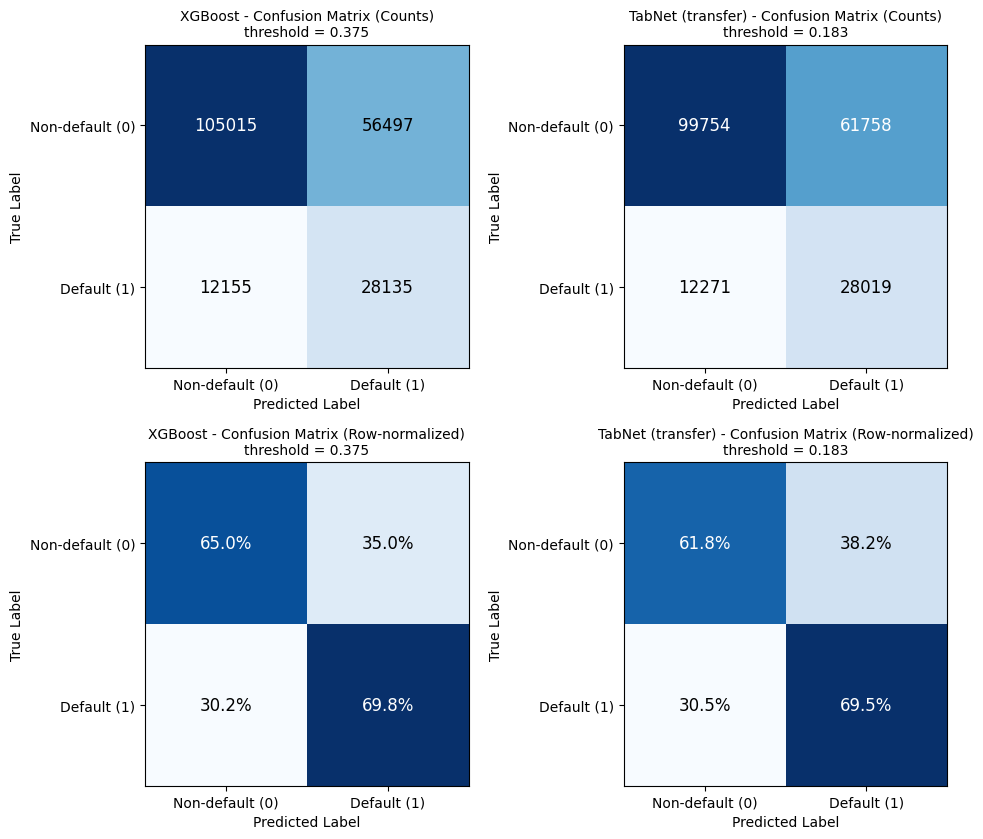

            model  threshold     TN    FP    FN    TP  recall  precision  f1_macro
          XGBoost     0.3752 105015 56497 12155 28135   0.698      0.332     0.602
TabNet (transfer)     0.1831  99754 61758 12271 28019   0.695      0.312     0.580
คัดลอกไป /content/drive/MyDrive/loan-Project/model_artifacts แล้ว


In [ ]:
labels = ["Non-default (0)", "Default (1)"]
pairs = [("XGBoost", p_xgb_va, p_xgb_te), ("TabNet (transfer)", p_tab_va, p_tab_te)]

fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
summ = []
for j, (name, pv, pt) in enumerate(pairs):
    thr = pick_threshold(y_va, pv, TARGET_RECALL)
    pred = (pt >= thr).astype(int)
    cm = confusion_matrix(y_te, pred, labels=[0, 1])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    for i, (mat, fmt, kind) in enumerate([(cm, "d", "Counts"), (cmn, ".1%", "Row-normalized")]):
        ax = axes[i, j]
        ax.imshow(mat, cmap="Blues")
        ax.set_title(f"{name} - Confusion Matrix ({kind})\nthreshold = {thr:.3f}", fontsize=10)
        ax.set_xticks([0, 1]); ax.set_xticklabels(labels); ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
        ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
        for r in range(2):
            for c in range(2):
                ax.text(c, r, format(mat[r, c], fmt), ha="center", va="center", fontsize=12,
                        color="white" if mat[r, c] > mat.max() * 0.6 else "black")
    tn, fp, fn, tp = cm.ravel()
    summ.append(dict(model=name, threshold=round(float(thr), 4), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp),
                     recall=round(tp / (tp + fn), 3), precision=round(tp / (tp + fp), 3) if tp + fp else np.nan,
                     f1_macro=round(f1_score(y_te, pred, average="macro"), 3)))
plt.tight_layout(); plt.savefig("confusion_matrix_compare.png", dpi=150); plt.show()
cm_summary = pd.DataFrame(summ)
print(cm_summary.to_string(index=False))
cm_summary.to_csv("confusion_matrix_summary.csv", index=False)

# คัดลอกผลลัพธ์ไป Drive ถ้า cell 12 รันแล้ว
try:
    import shutil
    for fn in ["learning_curves_compare.png", "learning_curves_compare.csv",
               "confusion_matrix_compare.png", "confusion_matrix_summary.csv"]:
        shutil.copy(fn, f"{SAVE_DIR}/{fn}")
    print("คัดลอกไป", SAVE_DIR, "แล้ว")
except NameError:
    print("ยังไม่ได้รัน cell 12 (SAVE_DIR) ไฟล์อยู่ใน /content เท่านั้น")